## 2. Análisis Exploratorio de Datos (EDA)

Proyecto: Análisis de la intención de compra en comercio electrónico mediante técnicas de minería de datos.

Dataset: Online Shoppers Purchasing Intention Dataset.

Objetivo

Explorar las características de las sesiones de navegación de los usuarios, identificar patrones en las variables numéricas y categóricas, analizar sus relaciones y estudiar las diferencias entre las sesiones que terminaron en una compra y aquellas que no.

Este análisis utiliza el conjunto de datos previamente limpiado por el equipo, sin repetir las operaciones de preprocesamiento.

## Configuración

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from google.colab import drive

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

sns.set_theme(style="whitegrid")


In [38]:
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/MyDrive/datos_limpios.csv')
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,TotalPages,NonProductDuration,ProductPageRatio,TotalDuration,AvgTimePerPage,IsSpecialDay,HasPageValue,conjunto
0,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,Feb,1,1,1,1,Returning_Visitor,0,0,1,0.0000,1.0000,0.0000,0.0000,0,0,train
1,0,0.0000,0,0.0000,2,64.0000,0.0000,0.1000,0.0000,0.0000,Feb,2,2,1,2,Returning_Visitor,0,0,2,0.0000,1.0000,64.0000,32.0000,0,0,test
2,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,Feb,4,1,9,3,Returning_Visitor,0,0,1,0.0000,1.0000,0.0000,0.0000,0,0,train
3,0,0.0000,0,0.0000,2,2.6667,0.0500,0.1400,0.0000,0.0000,Feb,3,2,2,4,Returning_Visitor,0,0,2,0.0000,1.0000,2.6667,1.3333,0,0,train
4,0,0.0000,0,0.0000,10,627.5000,0.0200,0.0500,0.0000,0.0000,Feb,3,3,1,4,Returning_Visitor,1,0,10,0.0000,1.0000,627.5000,62.7500,0,0,test


In [39]:
df = pd.read_csv("datos_limpios.csv")

print("Dimensiones del dataset:", df.shape)

display(df.head())

Dimensiones del dataset: (12205, 26)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,TotalPages,NonProductDuration,ProductPageRatio,TotalDuration,AvgTimePerPage,IsSpecialDay,HasPageValue,conjunto
0,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,Feb,1,1,1,1,Returning_Visitor,0,0,1,0.0000,1.0000,0.0000,0.0000,0,0,train
1,0,0.0000,0,0.0000,2,64.0000,0.0000,0.1000,0.0000,0.0000,Feb,2,2,1,2,Returning_Visitor,0,0,2,0.0000,1.0000,64.0000,32.0000,0,0,test
2,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,Feb,4,1,9,3,Returning_Visitor,0,0,1,0.0000,1.0000,0.0000,0.0000,0,0,train
3,0,0.0000,0,0.0000,2,2.6667,0.0500,0.1400,0.0000,0.0000,Feb,3,2,2,4,Returning_Visitor,0,0,2,0.0000,1.0000,2.6667,1.3333,0,0,train
4,0,0.0000,0,0.0000,10,627.5000,0.0200,0.0500,0.0000,0.0000,Feb,3,3,1,4,Returning_Visitor,1,0,10,0.0000,1.0000,627.5000,62.7500,0,0,test


Exploración inicial del conjunto de datos

En esta sección se examina la estructura del conjunto de datos previamente procesado, identificando el número de registros, las variables disponibles, sus tipos de datos y la presencia de valores faltantes.

Esta revisión permite verificar las características generales del dataset antes de realizar el análisis estadístico y las visualizaciones.

In [40]:
# Mostrar dimensiones del dataset
print("Dimensiones:", df.shape)

# Mostrar nombres de las columnas
print("\nColumnas disponibles:")
print(df.columns.tolist())

# Mostrar tipos de datos
print("\nInformación general:")
df.info()

Dimensiones: (12205, 26)

Columnas disponibles:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue', 'TotalPages', 'NonProductDuration', 'ProductPageRatio', 'TotalDuration', 'AvgTimePerPage', 'IsSpecialDay', 'HasPageValue', 'conjunto']

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12205 entries, 0 to 12204
Data columns (total 26 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12205 non-null  int64  
 1   Administrative_Duration  12205 non-null  float64
 2   Informational            12205 non-null  int64  
 3   Informational_Duration   12205 non-null  float64
 4   ProductRelated           12205 non-null  int64  
 5   ProductRela

In [41]:
# Contar valores faltantes por columna
faltantes = df.isnull().sum()

print("Valores faltantes por variable:")
display(faltantes.to_frame(name="Valores faltantes"))

print("Total de valores faltantes:", faltantes.sum())

Valores faltantes por variable:


,Valores faltantes
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


Total de valores faltantes: 0


In [42]:
# Verificar registros duplicados
duplicados = df.duplicated().sum()

print("Registros duplicados:", duplicados)

Registros duplicados: 0


In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12205 entries, 0 to 12204
Data columns (total 26 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12205 non-null  int64  
 1   Administrative_Duration  12205 non-null  float64
 2   Informational            12205 non-null  int64  
 3   Informational_Duration   12205 non-null  float64
 4   ProductRelated           12205 non-null  int64  
 5   ProductRelated_Duration  12205 non-null  float64
 6   BounceRates              12205 non-null  float64
 7   ExitRates                12205 non-null  float64
 8   PageValues               12205 non-null  float64
 9   SpecialDay               12205 non-null  float64
 10  Month                    12205 non-null  object 
 11  OperatingSystems         12205 non-null  int64  
 12  Browser                  12205 non-null  int64  
 13  Region                   12205 non-null  int64  
 14  TrafficType           

## Observaciones:

Hay 12205 observaciones y 26 columnas en el conjunto de datos.

Todas las columnas tienen 12205 valores no nulos, es decir, no faltan valores en los datos.

## Estadísticas descriptivas de las variables numéricas

Se calcularán medidas de tendencia central, dispersión y posición para las variables cuantitativas del conjunto de datos, con el propósito de identificar sus características generales, rangos de valores y posibles diferencias entre la media y la mediana.

Las variables categóricas codificadas numéricamente se excluyen de este cálculo, debido a que sus valores representan identificadores y no cantidades.

In [44]:
# Variables numéricas originales
variables_numericas = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]

# Variables numéricas derivadas
variables_derivadas = [
    "TotalPages",
    "NonProductDuration",
    "ProductPageRatio",
    "TotalDuration",
    "AvgTimePerPage"
]

# Unir las variables cuantitativas
columnas_analisis = variables_numericas + variables_derivadas

# Calcular estadísticas descriptivas
estadisticas = df[columnas_analisis].describe().T

# Agregar la mediana explícitamente
estadisticas["mediana"] = df[columnas_analisis].median()

# Ordenar las columnas
estadisticas = estadisticas[
    ["count", "mean", "mediana", "std",
     "min", "25%", "50%", "75%", "max"]
]

display(estadisticas)

,count,mean,mediana,std,min,25%,50%,75%,max
Administrative,"12,205.0000",2.3389,1.0000,3.3304,0.0000,0.0000,1.0000,4.0000,27.0000
Administrative_Duration,"12,205.0000",81.6463,9.0000,177.4918,0.0000,0.0000,9.0000,94.7000,"3,398.7500"
Informational,"12,205.0000",0.5087,0.0000,1.2756,0.0000,0.0000,0.0000,0.0000,24.0000
Informational_Duration,"12,205.0000",34.8255,0.0000,141.4248,0.0000,0.0000,0.0000,0.0000,"2,549.3750"
ProductRelated,"12,205.0000",32.0456,18.0000,44.5936,0.0000,8.0000,18.0000,38.0000,705.0000
ProductRelated_Duration,"12,205.0000","1,206.9825",608.9429,"1,919.6014",0.0000,193.0000,608.9429,"1,477.1548","63,973.5222"
BounceRates,"12,205.0000",0.0204,0.0029,0.0453,0.0000,0.0000,0.0029,0.0167,0.2000
ExitRates,"12,205.0000",0.0415,0.0250,0.0462,0.0000,0.0142,0.0250,0.0485,0.2000
PageValues,"12,205.0000",5.9496,0.0000,18.6537,0.0000,0.0000,0.0000,0.0000,361.7637
SpecialDay,"12,205.0000",0.0619,0.0000,0.1997,0.0000,0.0000,0.0000,0.0000,1.0000


## Interpretación de las estadísticas descriptivas

El análisis de las 12,205 sesiones muestra que los usuarios visitan principalmente páginas relacionadas con productos, con un promedio de 32.05 páginas por sesión, mientras que las páginas administrativas e informativas presentan promedios de 2.34 y 0.51, respectivamente.

Además, se observa que la mayoría de las sesiones no registra visitas a páginas informativas, ya que al menos el 75 % presenta un valor de cero en esta variable.

Por otra parte, en las páginas de productos existe una diferencia considerable entre la media (32.05) y la mediana (18), debido a la presencia de valores elevados, como el máximo de 705 páginas. Esto indica una distribución asimétrica, donde algunas sesiones con mucha actividad elevan el promedio y no representan el comportamiento habitual.

En conclusión, la navegación se concentra principalmente en la exploración de productos, mientras que las páginas informativas reciben poca atención. También se identifican valores extremos que influyen en los promedios, por lo que es importante considerar tanto la media como la mediana al interpretar los datos.

## Análisis gráfico de las variables numéricas


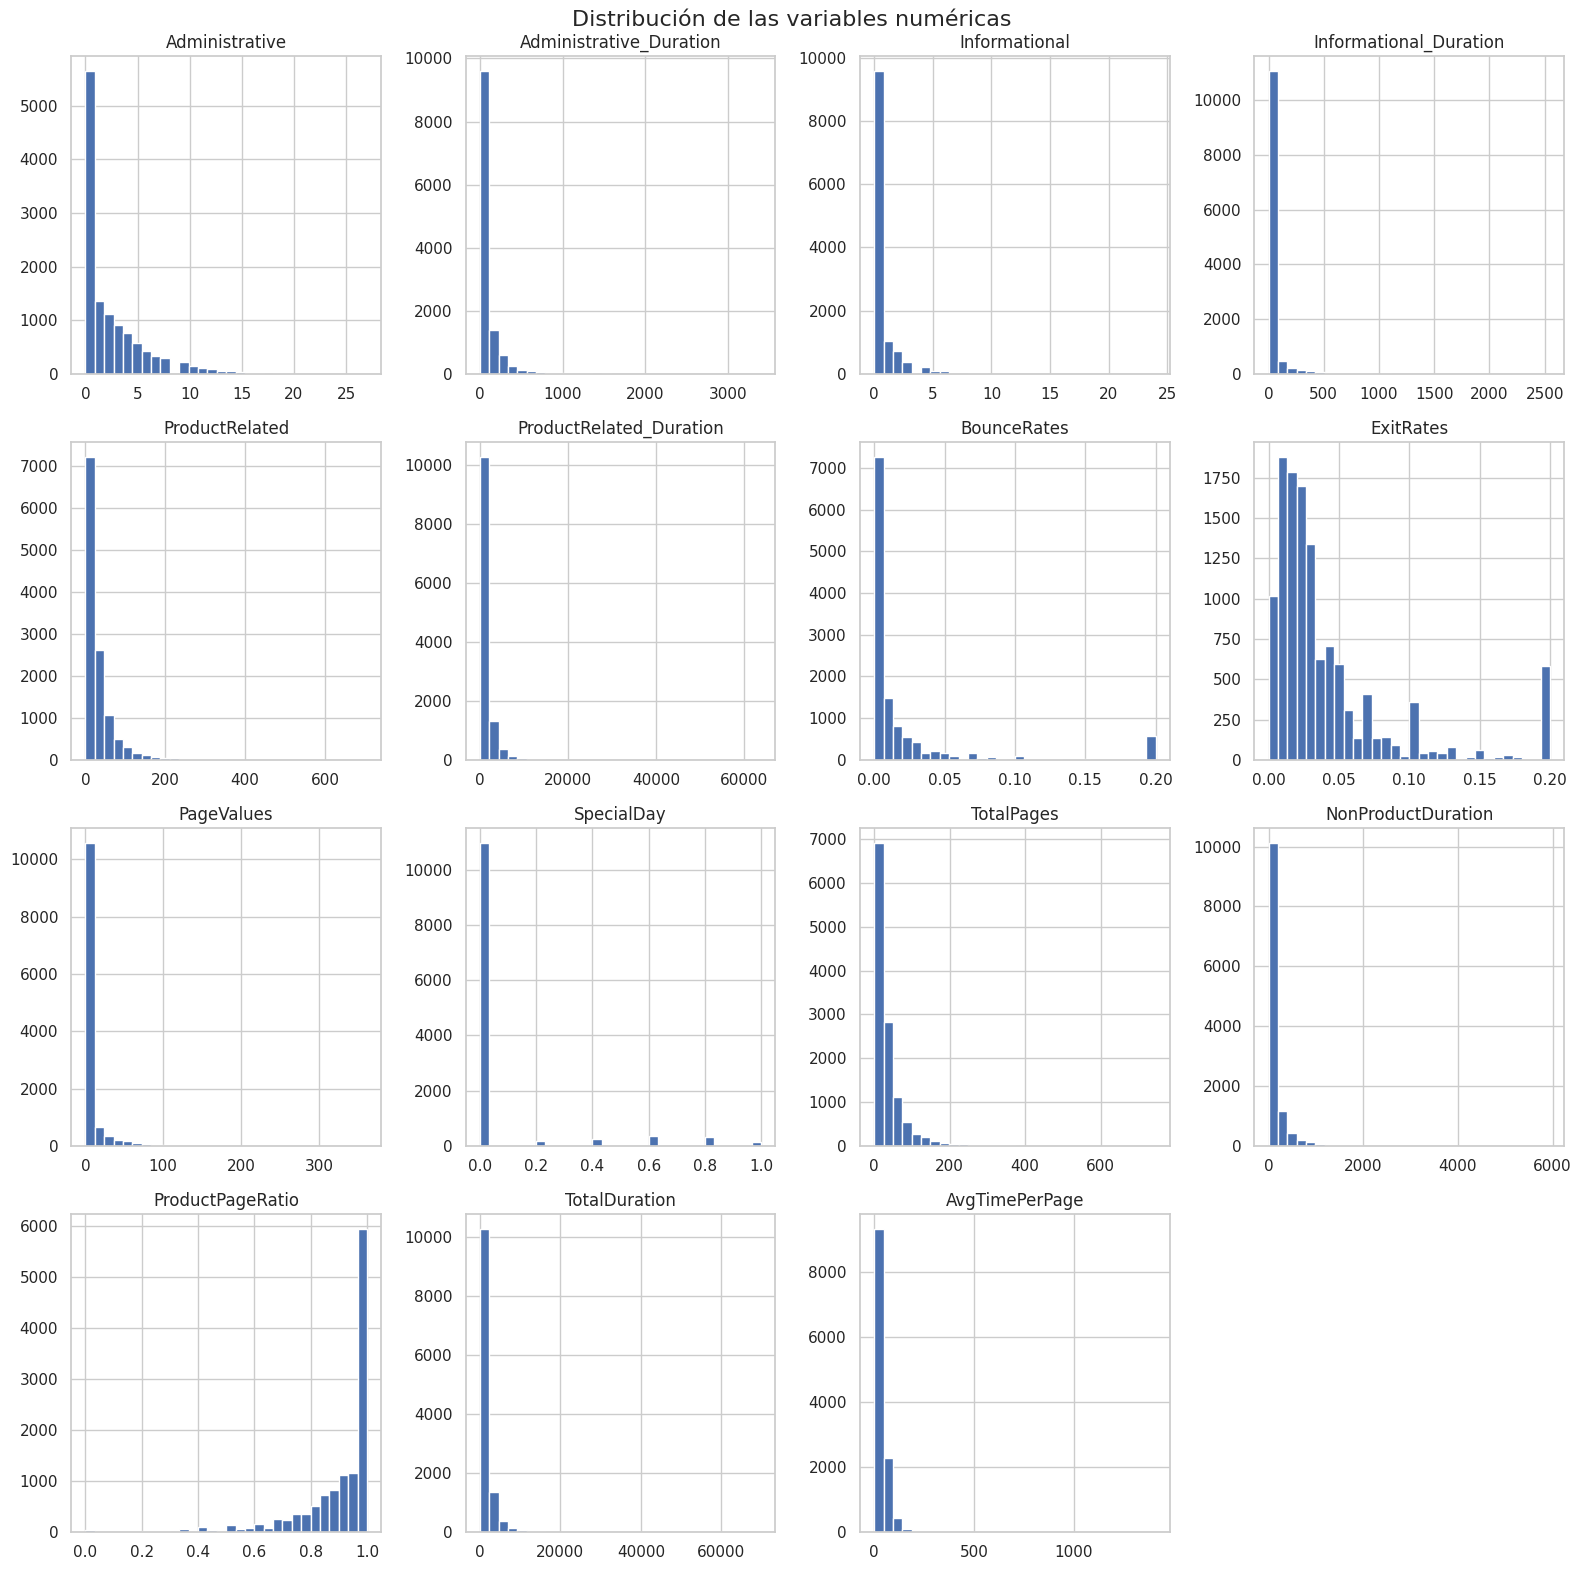

In [45]:
# Crear histogramas de las variables numéricas
df[columnas_analisis].hist(
    figsize=(16, 16),
    bins=30
)

plt.suptitle("Distribución de las variables numéricas", fontsize=16)
plt.tight_layout()
plt.show()

## Interpretación de los histogramas

Los histogramas muestran que la mayoría de las variables numéricas presentan una concentración de valores bajos o cercanos a cero, mientras que una menor cantidad de sesiones registra valores elevados. Esto genera distribuciones asimétricas hacia la derecha, especialmente en variables como ProductRelated, TotalDuration y PageValues.

En las variables administrativas e informativas se observa poca actividad, principalmente en las páginas informativas. Por otra parte, aunque ProductRelated también concentra muchas sesiones en valores bajos, presenta un rango de visitas considerablemente mayor, lo que refleja una mayor actividad en las páginas de productos.

Además, la variable ProductPageRatio presenta una concentración de valores cercanos a 1, lo que indica que gran parte de las páginas visitadas durante las sesiones corresponde a productos.



##Análisis univariante para variables categóricas

In [46]:
# Seleccionar variables categóricas
cat_cols = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend",
    "Revenue"
]

# Frecuencias y porcentajes por categoría
for i in cat_cols:
    print(f"\nVariable: {i}")

    print("\nPorcentajes:")
    print((df[i].value_counts(normalize=True) * 100).round(2))

    print("\nFrecuencias:")
    print(df[i].value_counts())

    print("-" * 40)


Variable: Month

Porcentajes:
Month
May   27.2800
Nov   24.4300
Mar   15.2400
Dec   13.9800
Oct    4.5000
Sep    3.6700
Aug    3.5500
Jul    3.5400
Jun    2.3400
Feb    1.4800
Name: proportion, dtype: float64

Frecuencias:
Month
May    3329
Nov    2982
Mar    1860
Dec    1706
Oct     549
Sep     448
Aug     433
Jul     432
Jun     285
Feb     181
Name: count, dtype: int64
----------------------------------------

Variable: OperatingSystems

Porcentajes:
OperatingSystems
2   53.5900
1   20.8800
3   20.7300
4    3.9200
8    0.6100
6    0.1600
7    0.0600
5    0.0500
Name: proportion, dtype: float64

Frecuencias:
OperatingSystems
2    6541
1    2549
3    2530
4     478
8      75
6      19
7       7
5       6
Name: count, dtype: int64
----------------------------------------

Variable: Browser

Porcentajes:
Browser
2    64.5900
1    19.8900
4     5.9900
5     3.8100
6     1.4300
10    1.3400
8     1.1100
3     0.8600
13    0.4600
7     0.4000
12    0.0800
11    0.0500
9     0.0100
Name: p

## Interpretación del análisis univariante de variables categóricas

El análisis de las 12,205 sesiones muestra que mayo fue el mes con mayor actividad, concentrando el 27.28 % de las sesiones, mientras que febrero registró la menor participación, con apenas el 1.48 %.

Asimismo, se observa que predominan los visitantes recurrentes, quienes representan el 85.46 % de las sesiones, frente al 13.87 % correspondiente a visitantes nuevos. También se identificó que la mayoría de las sesiones ocurrió entre semana (76.58 %).

Por último, la variable Revenue muestra que solo el 15.63 % de las sesiones terminó en una compra, mientras que el 84.37 % no generó una transacción.



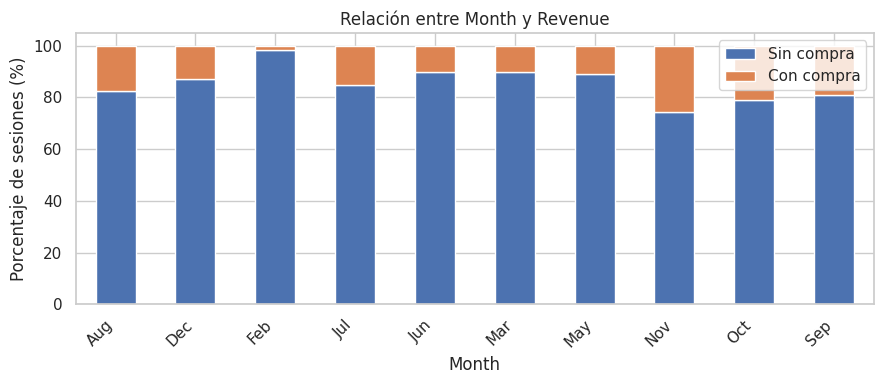

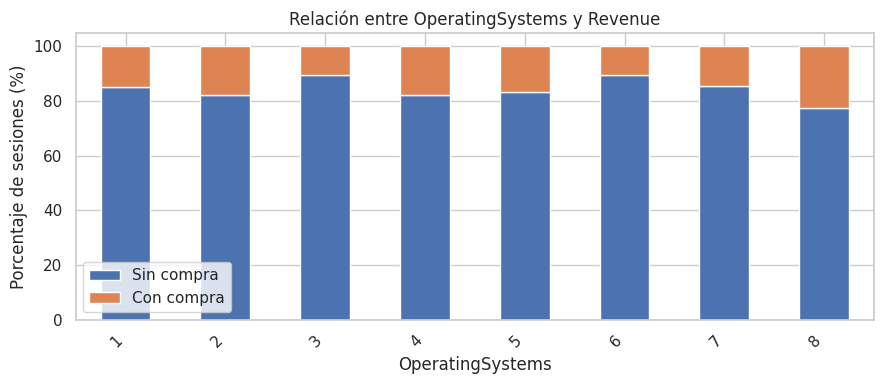

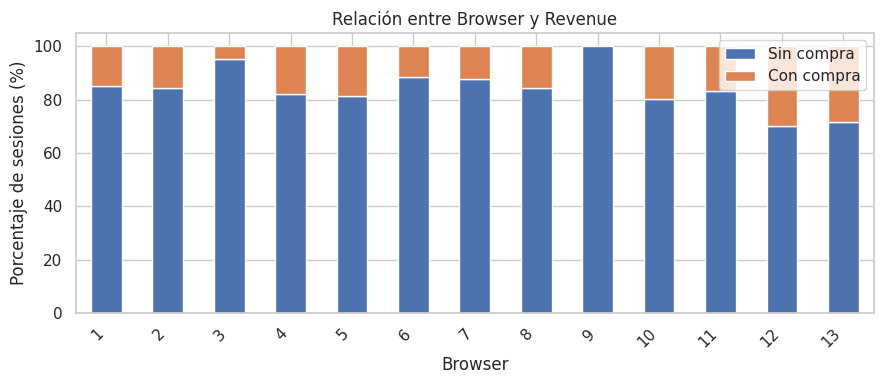

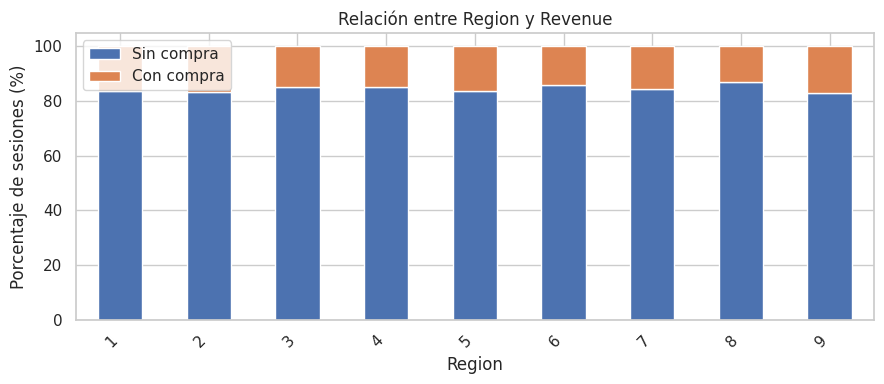

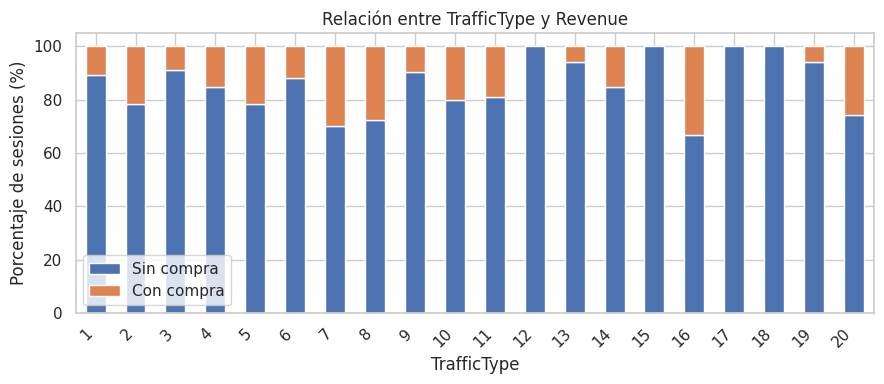

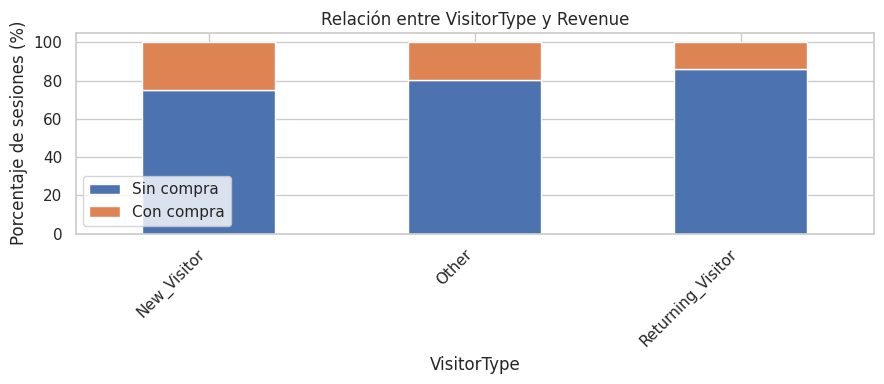

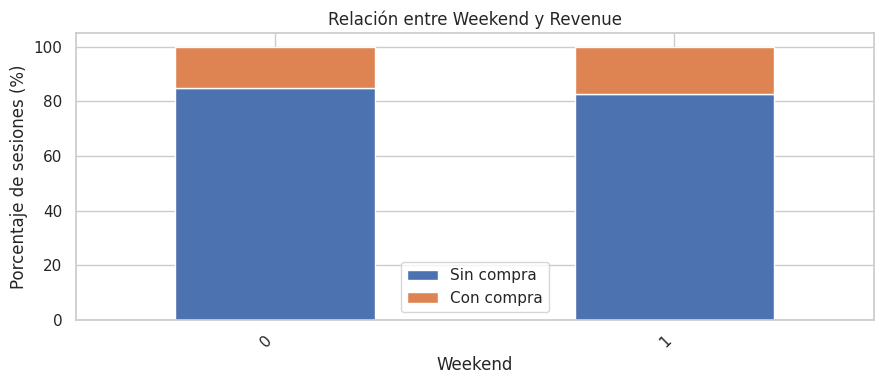

In [47]:
# Análisis bivariado: variables categóricas vs Revenue

for i in cat_cols:
    if i != 'Revenue':
        (pd.crosstab(
            df[i],
            df['Revenue'],
            normalize='index'
        ) * 100).plot(
            kind='bar',
            figsize=(9, 4),
            stacked=True
        )

        plt.title(f'Relación entre {i} y Revenue')
        plt.xlabel(i)
        plt.ylabel('Porcentaje de sesiones (%)')
        plt.legend(['Sin compra', 'Con compra'])
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()

## Interpretación del análisis bivariado de variables categóricas
Al comparar las variables categóricas con Revenue, se observa que noviembre presenta la mayor proporción de sesiones que terminan en compra (aproximadamente 25 %), mientras que febrero registra la menor. Esto resulta relevante porque mayo concentra la mayor cantidad de sesiones, pero no la mayor proporción de compras.

Asimismo, los visitantes nuevos presentan una mayor tasa de compra que los recurrentes, a pesar de que estos últimos representan la mayoría de las sesiones. También se observa que durante los fines de semana la proporción de compras es ligeramente superior a la registrada entre semana.

## Relación entre revenue y las variables numéricas



In [48]:
# Promedio de las variables numéricas según Revenue

df.groupby(['Revenue'])[columnas_analisis].mean().round(2)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,TotalPages,NonProductDuration,ProductPageRatio,TotalDuration,AvgTimePerPage
Revenue,,,,,,,,,,,,,,,
0,2.1400,74.6400,0.4600,30.6000,29.0500,"1,082.9800",0.0200,0.0500,2.0000,0.0700,31.6500,105.2400,0.9100,"1,188.2200",37.4700
1,3.3900,119.4800,0.7900,57.6100,48.2100,"1,876.2100",0.0100,0.0200,27.2600,0.0200,52.3900,177.0900,0.8900,"2,053.3000",42.0300


## Interpretación de las variables numéricas según Revenue

Al comparar los promedios de las variables numéricas según Revenue, se observa que las sesiones que terminan en compra presentan una mayor actividad de navegación. En promedio, visitan 48.21 páginas de productos, frente a 29.05 en las sesiones sin compra, y registran una duración total de 2,053.30 segundos, en comparación con 1,188.22 segundos.

Asimismo, las sesiones con compra presentan menores tasas de rebote y salida, lo que indica diferencias en los patrones de navegación entre ambos grupos.

Por otra parte, PageValues muestra una diferencia importante, con un promedio de 27.26 en las sesiones con compra y 2.00 en las sesiones sin compra.

In [49]:
# Mediana de las variables numéricas según Revenue
df.groupby('Revenue')[columnas_analisis].median().round(2)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,TotalPages,NonProductDuration,ProductPageRatio,TotalDuration,AvgTimePerPage
Revenue,,,,,,,,,,,,,,,
0,1.0000,0.0000,0.0000,0.0000,16.0000,526.0000,0.0000,0.0300,0.0000,0.0000,18.0000,9.0000,0.9700,600.7500,28.5700
1,2.0000,52.3700,0.0000,0.0000,29.0000,"1,109.9100",0.0000,0.0200,16.7600,0.0000,32.0000,69.0000,0.9300,"1,252.0800",36.2600


## Comparación de medianas según Revenue

Al comparar las medianas, se confirma que las sesiones que terminan en compra presentan una mayor actividad de navegación. Estas registran una mediana de 29 páginas de productos visitadas, frente a 16 en las sesiones sin compra, y una duración total de 1,252.08 segundos, en comparación con 600.75 segundos.

Asimismo, PageValues presenta una diferencia importante, con una mediana de 16.76 en las sesiones con compra y 0 en las sesiones sin compra. También se observa una menor tasa de salida en las sesiones que terminan en compra.

##Relación entre diferentes variables numéricas

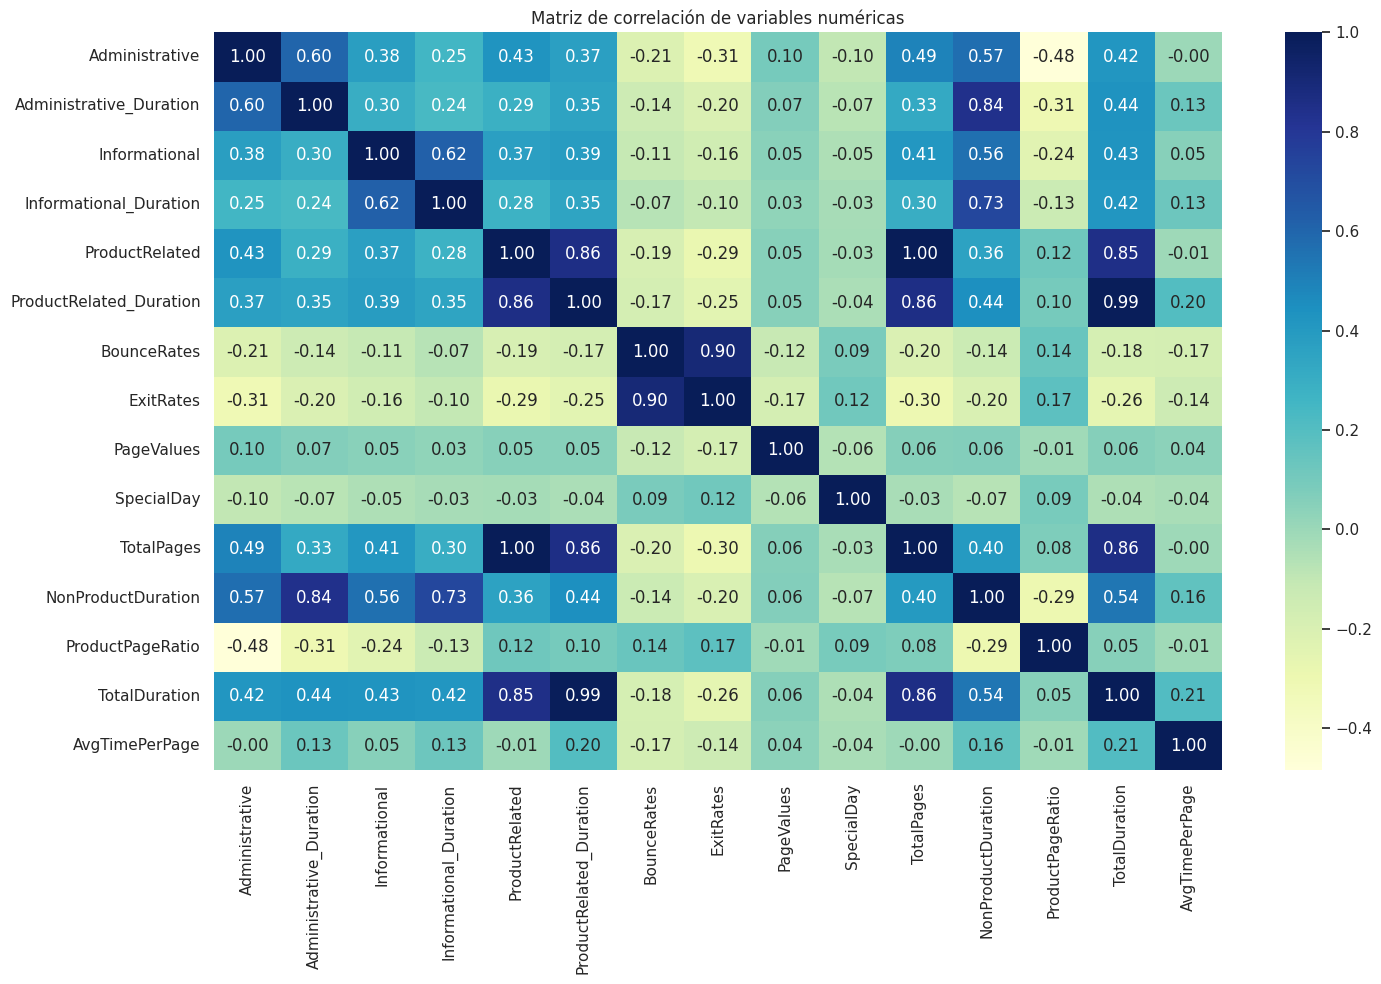

In [50]:
# Correlación entre variables numéricas

plt.figure(figsize=(15, 10))

sns.heatmap(
    df[columnas_analisis].corr(),
    annot=True,
    fmt='.2f',
    cmap='YlGnBu'
)

plt.title('Matriz de correlación de variables numéricas')
plt.tight_layout()
plt.show()

## Interpretación de la matriz de correlación

La matriz de correlación muestra relaciones positivas fuertes entre varias variables relacionadas con la actividad de navegación. Destacan ProductRelated_Duration y TotalDuration (0.99), ProductRelated y TotalPages (1.00), así como TotalPages y TotalDuration (0.86). Estas asociaciones indican que las sesiones con mayor cantidad de páginas visitadas tienden a registrar una mayor duración. Algunas de estas correlaciones son esperables, ya que las variables derivadas se calculan a partir de otras.

También se observa una correlación positiva fuerte entre BounceRates y ExitRates (0.90), lo que indica que ambas tasas tienden a aumentar conjuntamente.

Por otra parte, Administrative y ProductPageRatio presentan una correlación negativa moderada (-0.48), lo que sugiere que las sesiones con mayor actividad administrativa tienden a dedicar una menor proporción de sus visitas a páginas de productos.

Finalmente, PageValues presenta correlaciones bajas con la mayoría de las variables analizadas.

## Relación entre diferentes variables numéricas con Revenue

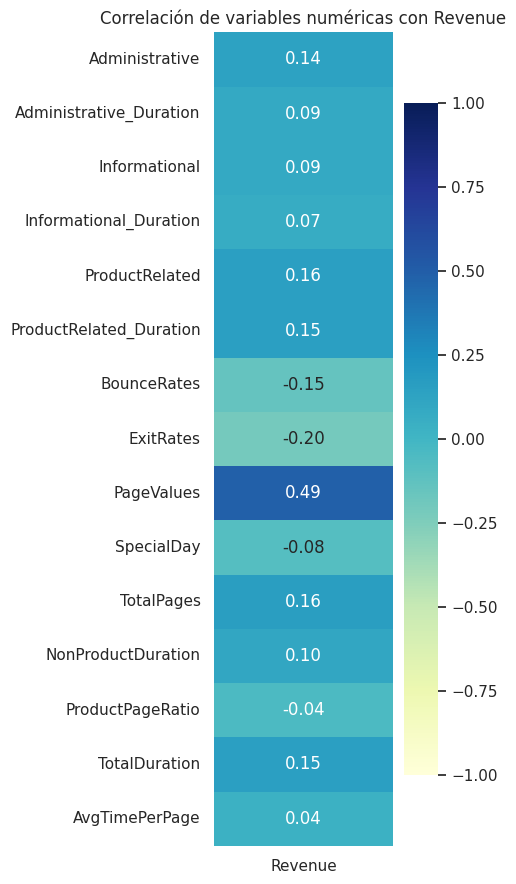

In [51]:
# Correlación de las variables numéricas con Revenue

correlaciones = df[columnas_analisis + ['Revenue']].corr()

plt.figure(figsize=(5, 9))

sns.heatmap(
    correlaciones[['Revenue']].drop('Revenue'),
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    vmin=-1,
    vmax=1
)

plt.title('Correlación de variables numéricas con Revenue')
plt.tight_layout()
plt.show()

## Interpretación de la correlación con Revenue

La mayoría de las variables numéricas presentan correlaciones débiles con Revenue. La asociación más destacada corresponde a PageValues (0.49), que muestra una correlación positiva moderada con la realización de compras.

Por otra parte, ExitRates (-0.20) y BounceRates (-0.15) presentan correlaciones negativas débiles, lo que indica que las sesiones con mayores tasas de salida y rebote tienden a asociarse con una menor probabilidad de compra.

Variables relacionadas con la actividad de navegación, como ProductRelated (0.16), TotalPages (0.16) y TotalDuration (0.15), muestran correlaciones positivas, aunque de baja intensidad.

## Boxplots de variables numéricas

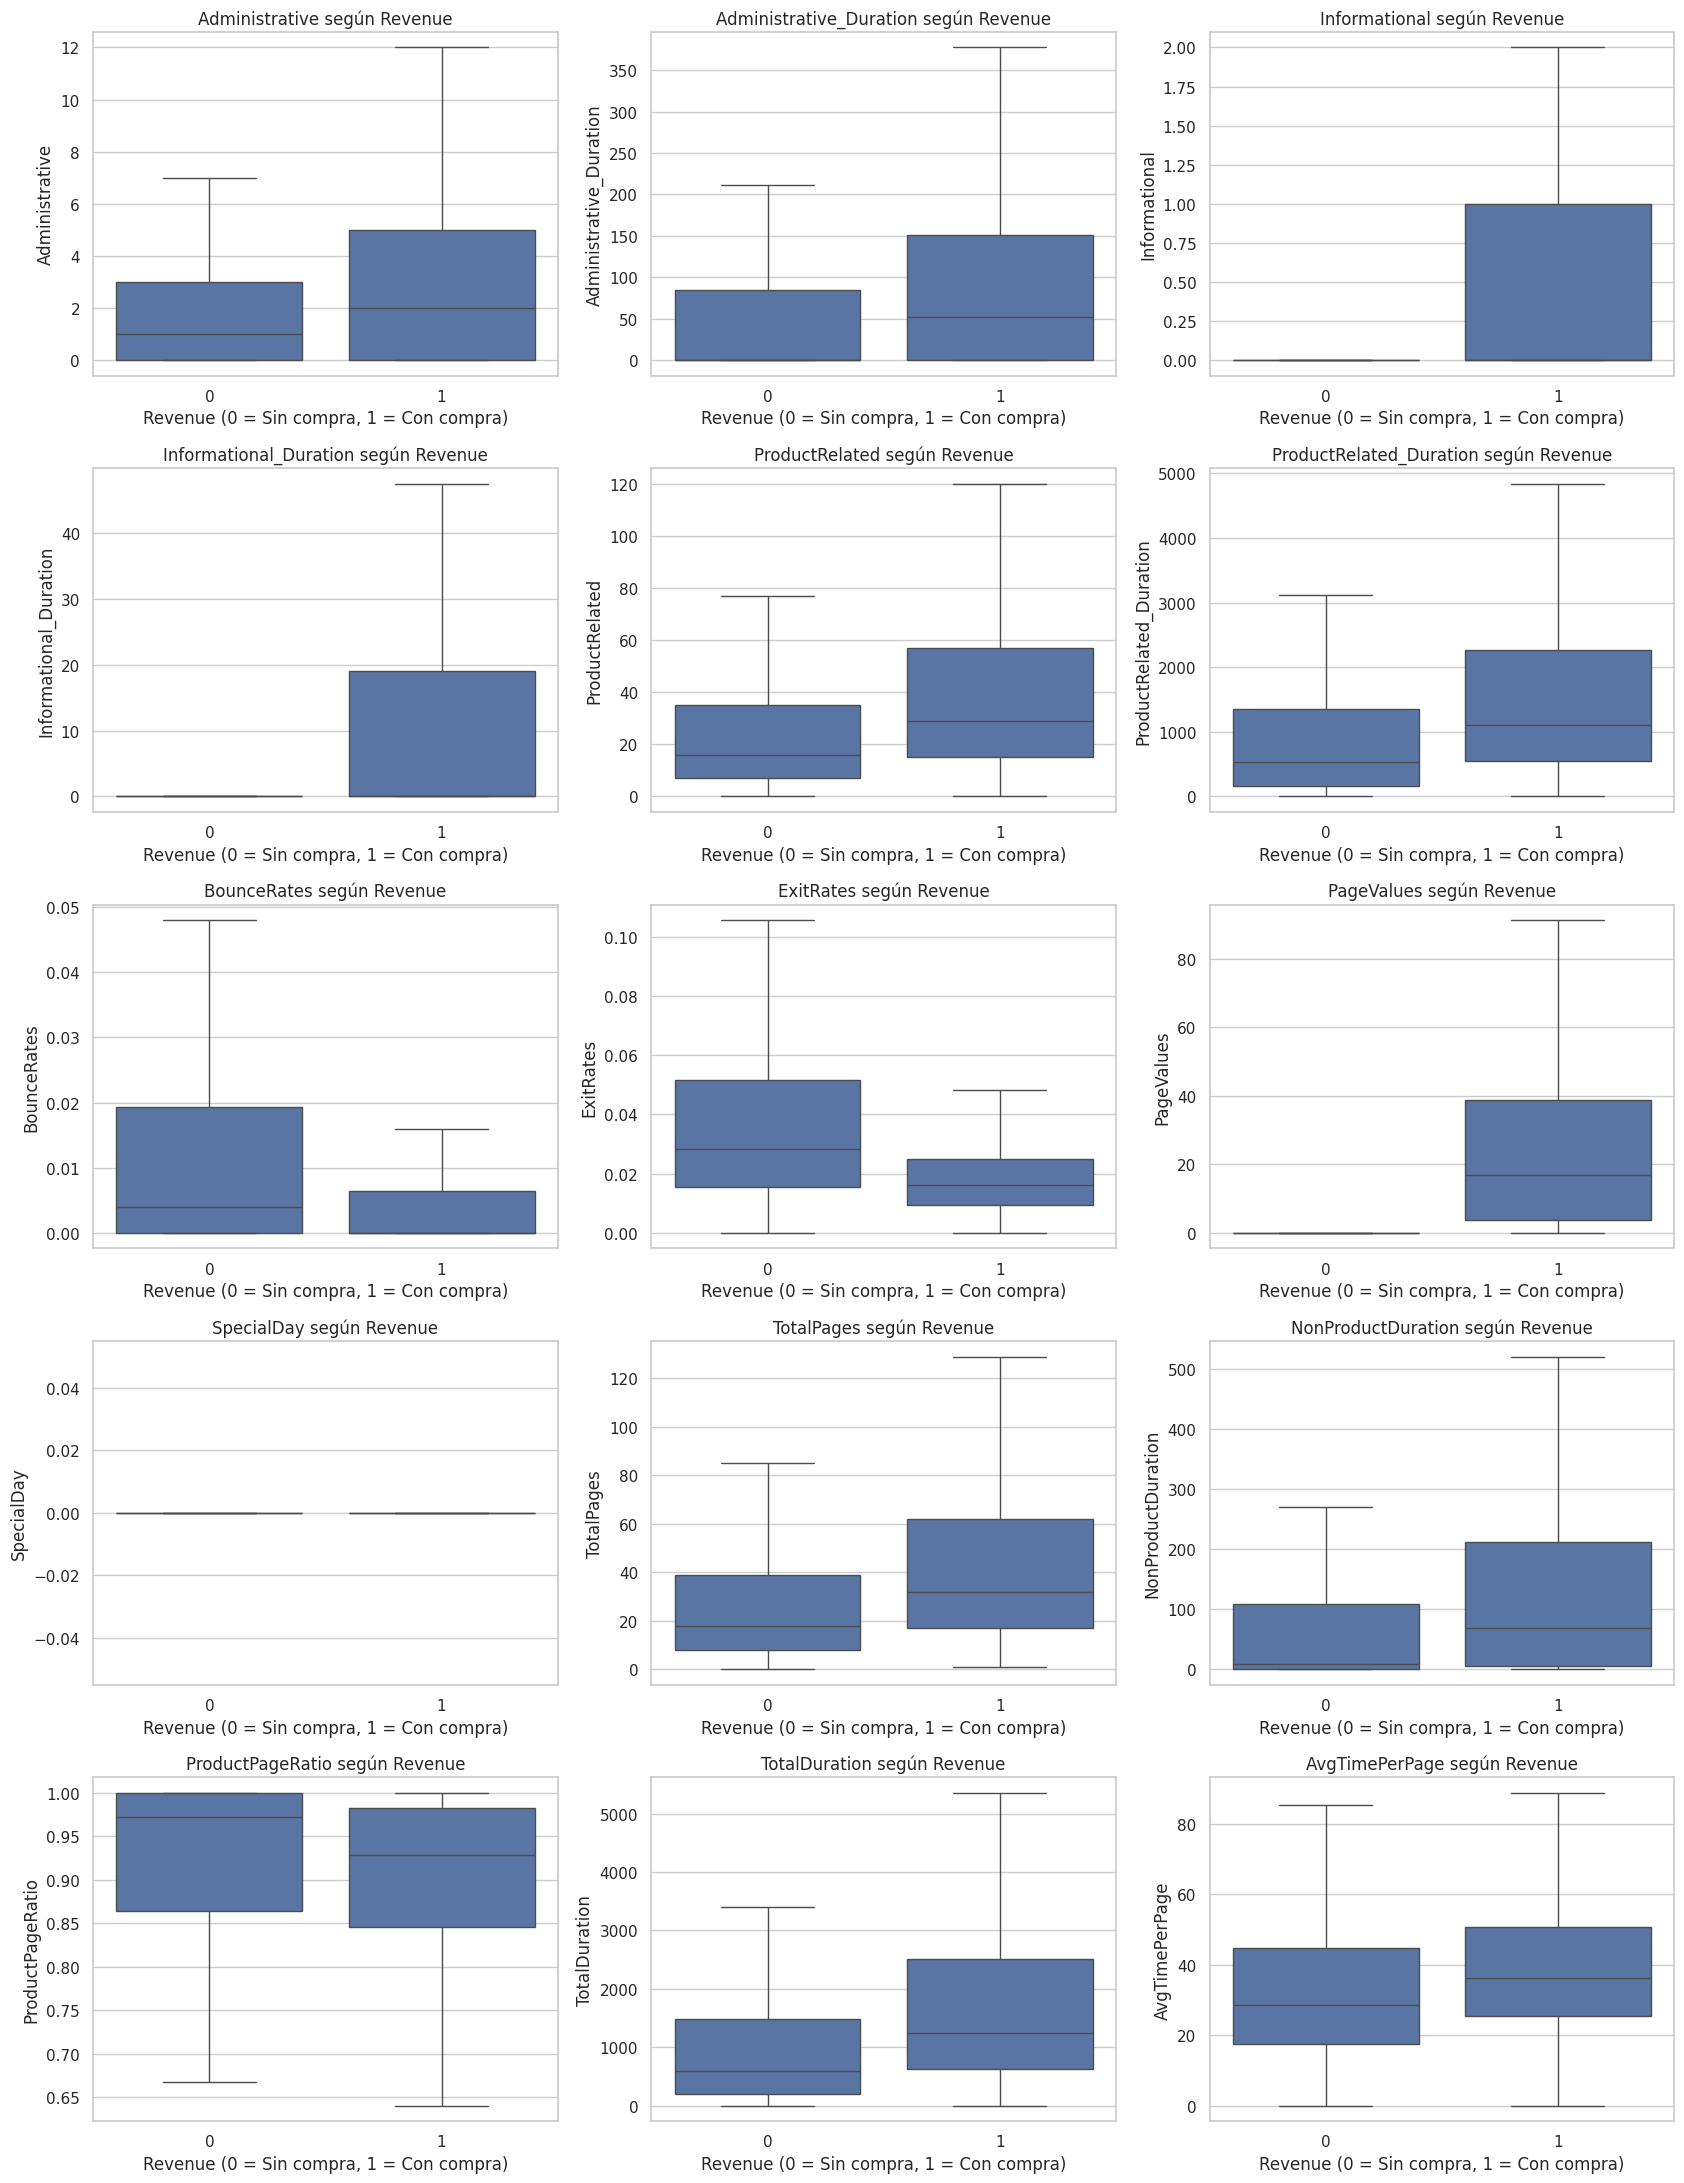

In [52]:
# Boxplots de las 15 variables numéricas según Revenue

fig, axes = plt.subplots(5, 3, figsize=(17, 22))

for ax, variable in zip(axes.flatten(), columnas_analisis):
    sns.boxplot(
        data=df,
        x='Revenue',
        y=variable,
        showfliers=False,
        ax=ax
    )

    ax.set_title(f'{variable} según Revenue')
    ax.set_xlabel('Revenue (0 = Sin compra, 1 = Con compra)')
    ax.set_ylabel(variable)

plt.tight_layout()
plt.show()

## Interpretación de Boxplots
Los diagramas de caja muestran diferencias importantes entre las sesiones que terminan en compra (Revenue = 1) y aquellas que no (Revenue = 0).

En ProductRelated, las sesiones con compra presentan una mediana de 29 páginas de productos visitadas, frente a 16 en las sesiones sin compra. Asimismo, ProductRelated_Duration muestra que las sesiones con compra dedican más tiempo a explorar productos, con una mediana de 1,109.91 segundos, frente a 526 segundos.

Esta diferencia también se observa en TotalDuration, cuya mediana es de 1,252.08 segundos para las sesiones con compra y de 600.75 segundos para las sesiones sin compra. Además, las cajas de estas tres variables muestran una mayor dispersión en el grupo con compra.

Por último, PageValues presenta una diferencia especialmente marcada: las sesiones sin compra tienen una mediana de 0, mientras que las sesiones con compra alcanzan 16.76. Esto indica que el valor de las páginas tiende a ser considerablemente mayor en las sesiones que terminan en compra.

## Grafico de dispersión

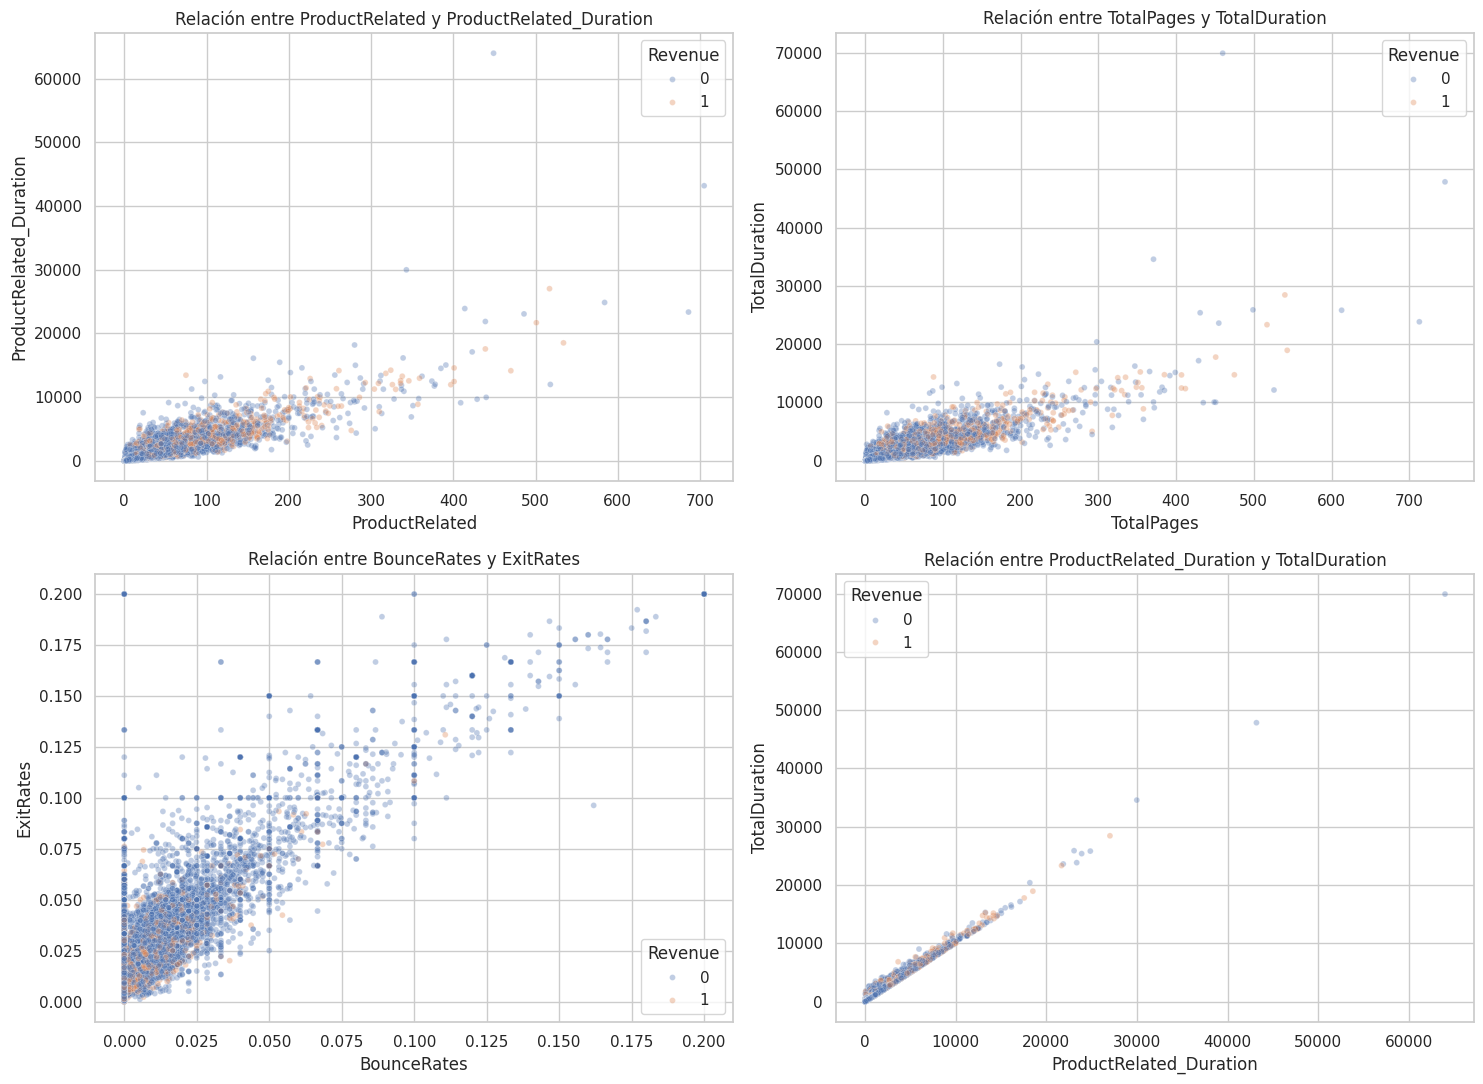

In [53]:
# Gráficos de dispersión entre variables numéricas

pares_variables = [
    ('ProductRelated', 'ProductRelated_Duration'),
    ('TotalPages', 'TotalDuration'),
    ('BounceRates', 'ExitRates'),
    ('ProductRelated_Duration', 'TotalDuration')
]

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

for ax, (x, y) in zip(axes.flatten(), pares_variables):
    sns.scatterplot(
        data=df,
        x=x,
        y=y,
        hue='Revenue',
        alpha=0.35,
        s=18,
        ax=ax
    )

    ax.set_title(f'Relación entre {x} y {y}')
    ax.legend(title='Revenue')

plt.tight_layout()
plt.show()

## Interpretación de los gráficos de dispersión

Los gráficos de dispersión muestran relaciones positivas entre las variables relacionadas con la navegación. Se observa que las sesiones con mayor cantidad de páginas de productos visitadas tienden a dedicar más tiempo a ellas (r = 0.86), y que un mayor número total de páginas se relaciona con una mayor duración de la sesión (r = 0.86).

Asimismo, BounceRates y ExitRates presentan una relación positiva fuerte (r = 0.90), mientras que ProductRelated_Duration y TotalDuration muestran una relación casi perfecta (r = 0.99), debido a que el tiempo dedicado a productos forma parte de la duración total.

También se identifican algunas sesiones con valores extremos. Aunque las sesiones con compra y sin compra presentan diferencias en sus características de navegación, sus puntos se superponen considerablemente, sin formar grupos claramente separados en estas gráficas.